# SGWB from the galaxy hosts of SMBHBs

This order-of-magnitude estimate will attempt to calculate what the strength of the stochastic background would be from a population of SMBHBs hosted in the galaxies attributed to host SMBHBs based on simulations/observations. We will do this by:

1. Identifying the number density of galaxies predicted to host SMBHBs through stellar mass and redshift
2. Using stellar mass - black hole mass scaling relations, calculate the total mass of the SMBHB system in each galaxy
3. Determine the GW signal from the binary system in each galaxy
4. Compare this to the SGWB to determine how likely it is that this population is from this galaxy type

Galactic hosts: SMBHBs are predicted to be hosted by massive early-type (elliptical) galaxies.

## Schechter function


In terms of $x=M/M^*$ the (double) Schechter function per unit mass is

$\Phi(M)\,dM = e^{-x}\left[\phi^*_1 x^{\alpha_1} + \phi^*_2 x^{\alpha_2}\right] dx$,

and per dex (what the code evaluates, using $dM = M\ln 10\, d\log_{10}M$) it is

$\Phi(\log_{10}M) = \ln 10\; e^{-x}\left[\phi^*_1 x^{\alpha_1+1} + \phi^*_2 x^{\alpha_2+1}\right]\;\;[\mathrm{Mpc^{-3}\,dex^{-1}}]$.

The tabulated $\phi^{*}$ are in Mpc$^{-3}$ (the standard Schechter normalisation), so the $\ln 10$ is required.

In [55]:
# double Schechter function
def double_schechter(m, phi1, m1, alpha1, phi2, m2, alpha2):
    """
    Double Schechter function.

    Parameters
    ----------
    m : array_like
        Masses at which to evaluate the function.
    phi1 : float
        Normalization of the first Schechter function.
    m1 : float
        Characteristic mass of the first Schechter function.
    alpha1 : float
        Low-mass slope of the first Schechter function.
    phi2 : float
        Normalization of the second Schechter function.
    m2 : float
        Characteristic mass of the second Schechter function.
    alpha2 : float
        Low-mass slope of the second Schechter function.

    Returns
    -------
    array_like
        Values of the double Schechter function at the specified masses.
    """
    term1 = np.log(10) * phi1 * 10**(np.log10(m / m1) * (alpha1 + 1)) * np.exp(-10**(np.log10(m / m1)))
    term2 = np.log(10) * phi2 * 10**(np.log10(m / m2) * (alpha2 + 1)) * np.exp(-10**(np.log10(m / m2)))
    return term1 + term2

def single_schechter(m, phi, m_star, alpha):
    """
    Single Schechter function.

    Parameters
    ----------
    m : array_like
        Masses at which to evaluate the function.
    phi : float
        Normalization of the Schechter function.
    m_star : float
        Characteristic mass of the Schechter function.
    alpha : float
        Low-mass slope of the Schechter function.

    Returns
    -------
    array_like
        Values of the single Schechter function at the specified masses.
    """
    return np.log(10) * phi * 10**(np.log10(m / m_star) * (alpha + 1)) * np.exp(-10**(np.log10(m / m_star)))

Early type galaxies - spheroids in this paper: https://academic.oup.com/mnras/article/462/4/4495/2589496?utm_source=chatgpt.com&login=false#92794859

In [56]:
# at z = 0.2-0.5
schech_params_z_0_2_0_5 = {
    "phi1": 0.75e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.59,  # M_sun
    "alpha1": -0.25,
    "phi2": 0.07e-3,  # Mpc^-3 (Schechter phi*)
    "m2": 10**10.59,  # M_sun
    "alpha2": -1.6,
}

# at z = 0.5-0.8
schech_params_z_0_5_0_8 = {
    "phi1": 0.91e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.89,  # M_sun
    "alpha1": -0.51,
    "phi2": 0.06e-3,  # Mpc^-3 (Schechter phi*)
    "m2": 10**10.89,  # M_sun
    "alpha2": -1.6,
}

# at z = 0.8-1.1
single_schech_params_z_0_8_1_1 = {
    "phi1": 0.48e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**11.01,  # M_sun
    "alpha1": -1.00,
}

# at z = 1.1-1.5
single_schech_params_z_1_1_1_5 = {
    "phi1": 0.46e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.80,  # M_sun
    "alpha1": -0.78,
}

# at z = 1.5-2.0
single_schech_params_z_1_5_2_0 = {
    "phi1": 0.59e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.52,  # M_sun
    "alpha1": 0.24,
}

# at z = 2.0-2.5
single_schech_params_z_2_0_2_5 = {
    "phi1": 0.23e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.76,  # M_sun
    "alpha1": -0.26,
}

# at z = 2.5-3.0
single_schech_params_z_2_5_3_0 = {
    "phi1": 0.09e-3,  # Mpc^-3 (Schechter phi*)
    "m1": 10**10.45,  # M_sun
    "alpha1": 0.74,
}

In [57]:
import numpy as np
import astropy.constants as const
import astropy.units as u
from scipy.integrate import cumulative_trapezoid, trapezoid
from astropy.cosmology import Planck18 as cosmo

G, c = const.G.si.value, const.c.si.value
Msun = const.M_sun.si.value
yr   = 365.25 * 86400
Gyr  = 1e9 * yr
Mpc  = const.pc.si.value * 1e6

edges     = [(0.2,0.5),(0.5,0.8),(0.8,1.1),(1.1,1.5),(1.5,2.0),(2.0,2.5),(2.5,3.0)]
params    = [schech_params_z_0_2_0_5, schech_params_z_0_5_0_8, single_schech_params_z_0_8_1_1,
             single_schech_params_z_1_1_1_5, single_schech_params_z_1_5_2_0,
             single_schech_params_z_2_0_2_5, single_schech_params_z_2_5_3_0]
mcomplete = [8.43, 8.94, 9.29, 9.61, 10.02, 10.21, 10.36]
bins = [(zlo, zhi, p, mc) for (zlo, zhi), p, mc in zip(edges, params, mcomplete)]   # BEFORE sample_lightcone

In [58]:
def bin_density(logm, p):
    """dN/dV/dlog10M for one bin. Detects single vs double by the keys."""
    m = 10**np.asarray(logm)
    if "phi2" in p:
        return double_schechter(m, p["phi1"], p["m1"], p["alpha1"],
                                   p["phi2"], p["m2"], p["alpha2"])
    return single_schechter(m, p["phi1"], p["m1"], p["alpha1"])

# ---- sample masses for one bin ----------------------------------------
def sample_logmass_bin(p, n, logm_min, logm_max, ngrid=5000, rng=None):
    rng = rng or np.random.default_rng()
    grid = np.linspace(logm_min, logm_max, ngrid)
    cdf = cumulative_trapezoid(bin_density(grid, p), grid, initial=0.0)
    cdf /= cdf[-1]
    return np.interp(rng.uniform(size=n), cdf, grid)

# ---- full lightcone: (z, logM) for a survey area ----------------------
def sample_lightcone(area_deg2, rng, logm_max=12.5, ngrid=5000, logm_floor=None):
    frac = area_deg2 * (np.pi/180)**2 / (4*np.pi)
    z, logm, V, dt = [], [], [], []
    for zlo, zhi, p, mc in bins:                  # mc = log M_complete
        lo = mc if logm_floor is None else max(mc, logm_floor)
        grid = np.linspace(lo, logm_max, ngrid)
        Vk = frac * (cosmo.comoving_volume(zhi) - cosmo.comoving_volume(zlo)).to(u.Mpc**3).value
        dtk = (cosmo.lookback_time(zhi) - cosmo.lookback_time(zlo)).to(u.s).value
        N = rng.poisson(trapezoid(bin_density(grid, p), grid) * Vk)
        if N == 0: continue
        zg = np.linspace(zlo, zhi, 500)
        cz = cumulative_trapezoid(cosmo.differential_comoving_volume(zg).value, zg, initial=0); cz /= cz[-1]
        z.append(np.interp(rng.uniform(size=N), cz, zg))
        logm.append(sample_logmass_bin(p, N, mc, logm_max, ngrid, rng))
        V.append(np.full(N, Vk)); dt.append(np.full(N, dtk))
    return [np.concatenate(a) for a in (z, logm, V, dt)]

def find_bin(z):
    for zlo, zhi, p, mc in bins:
        if zlo <= z < zhi: return p, mc
    raise ValueError(f"z={z} outside range")

rng = np.random.default_rng(1)
area_deg2 = 1000.0
f_sky = area_deg2 * (np.pi/180)**2 / (4*np.pi)
z, logm, V, dt = sample_lightcone(area_deg2=area_deg2, rng=rng)

# check: mass density above the cutoff (should be ≲ the table's ρ*)
def rho_star(p, logm_min, logm_max=13.5, ngrid=20000):
    g = np.linspace(logm_min, logm_max, ngrid)
    return trapezoid(bin_density(g, p) * 10**g, g)     # M_sun Mpc^-3

table_rho = [7.51, 7.85, 7.69, 7.42, 7.34, 7.09, 6.62]     # SPH, log10 rho_*
for (zlo, zhi, p, mc), tab in zip(bins, table_rho):
    print(f"{zlo}-{zhi}: table {tab:.2f}  mine {np.log10(rho_star(p, mc)):.2f}")

0.2-0.5: table 7.51  mine 7.50
0.5-0.8: table 7.85  mine 7.85
0.8-1.1: table 7.69  mine 7.68
1.1-1.5: table 7.42  mine 7.41
1.5-2.0: table 7.34  mine 7.33
2.0-2.5: table 7.09  mine 7.06
2.5-3.0: table 6.62  mine 6.57


# Black hole - galactic mass scaling relations

$\log_{10}\left(\frac{M_{\bullet}}{10^9\,\rm{M}_{\odot}}\right) = \log_{10}A + \beta\,\log_{10}\left(\frac{M_{\rm bulge}}{10^{11}\,\rm{M}_{\odot}}\right)$



From Kormendy & Ho (2013; https://www.annualreviews.org/docserver/fulltext/astro/51/1/annurev-astro-082708-101811.pdf?expires=1790229499&id=id&accname=au&checksum=57E25AC0AAF09C8AA095742693231602), we have: 

$\frac{M_{\bullet}}{10^9\,\rm{M}_{\odot}} = (0.49^{+0.06}_{-0.05}) \left(\frac{M_{\mathrm{bulge}}}{10^{11}\;\mathrm{M}_{\odot}} \right)^{1.17\pm0.08} $; with intrinsic scatter $= 0.28$ dex.


For early-type galaxies, $M_{\mathrm{bulge}} \approx M^*$.

In [59]:
import numpy as np

def draw_relation_params(rng, include_param_unc=True, alpha=0.49, alpha_up=0.06, alpha_down=0.05, beta=1.17, beta_err=0.08, z=0.0, alpha_evo=0.84):
    """
    Draw the population-level parameters (A, beta) of the M_BH-M_bulge relation.

    These describe the relation itself, so they are drawn ONCE per mock universe
    and shared by every galaxy. Only the intrinsic scatter is drawn per galaxy.

    Parameters
    ----------
    rng : np.random.Generator
    include_param_unc : bool
        If True, propagate the uncertainty on A and beta.
        If False, return the best-fit values.
    z : float
        Redshift.

    Returns
    -------
    A, beta : float
        Normalisation (in units of 1e9 M_sun) and slope.
    """
    alpha_mean, alpha_err_lo, alpha_err_hi = alpha, alpha_down, alpha_up
    beta_mean, beta_err = beta, beta_err

    if not include_param_unc:
        return alpha_mean, beta_mean

    # asymmetric error on A: split normal (Gaussian with a different width on each side)
    x = rng.normal()
    alpha = alpha_mean + x * (alpha_err_lo if x < 0 else alpha_err_hi)
    alpha *= (1 + z)**(alpha_evo)  # evolve alpha with redshift
    # symmetric error on beta
    beta = rng.normal(beta_mean, beta_err)
    return alpha, beta



def sample_MBH(M_bulge, A, beta, rng, scatter=0.28, scatter_ev = 0.56, z= 0.0):
    """
    Sample one M_BH per galaxy from:
    M_BH / 1e9 = A * (M_bulge / 1e11)^beta   (Kormendy & Ho 2013)

    Parameters
    ----------
    M_bulge : array_like
        Bulge stellar masses in solar masses (one per galaxy).
    A, beta : float
        Relation parameters from draw_relation_params.
    rng : np.random.Generator
    scatter : float
        Intrinsic scatter in dex.
    scatter_ev : float
        Evolution of the intrinsic scatter with redshift.
    z : float
        Redshift.

    Returns
    -------
    M_BH : ndarray
        Black hole masses in solar masses, same shape as M_bulge.
    """
    M_bulge = np.asarray(M_bulge)

    # --- Step 1: mean relation in log space ---
    log_MBH_mean = np.log10(A) + 9 + beta * np.log10(M_bulge / 1e11)
    
    # --- Step 1.5: evolve scatter with redshift ---
    scatter_z = scatter + (scatter_ev) * np.log10(1 + z)  # evolve scatter with redshift
    # --- Step 2: add intrinsic scatter (Gaussian in dex), independent per galaxy ---
    log_MBH = log_MBH_mean + rng.normal(0, scatter, M_bulge.shape)

    return 10**log_MBH


def chirp_mass(m1, m2):
    """Chirp mass, M_c = (m1 m2)^(3/5) / (m1 + m2)^(1/5). Same units as the inputs."""
    return (m1 * m2)**(3/5) / (m1 + m2)**(1/5)



def make_binaries(logM_star, rng, q_min=0.25, include_param_unc=True, z=0.0):
    """
    Turn sampled galaxies into black hole binaries.

    For each galaxy (the primary), draw a galaxy mass ratio, get the partner's
    stellar mass, and convert both to BH masses with the scaling relation.

    Parameters
    ----------
    logM_star : array_like
        log10 stellar mass of each primary galaxy (M_bulge ~ M_* for spheroids).
    rng : np.random.Generator
    q_min : float
        Minimum galaxy mass ratio; q_gal is drawn uniformly in [q_min, 1].
    include_param_unc : bool
        Whether to propagate uncertainty on A and beta.

    Returns
    -------
    m1, m2 : ndarray
        BH masses in solar masses, with m1 >= m2.
    """
    logM_star = np.asarray(logM_star)

    z = np.asarray(z)

    # --- Step 1: one set of relation parameters for this whole realisation ---
    A, beta = draw_relation_params(rng, include_param_unc, z=z)

    # --- Step 2: galaxy mass ratio and the partner's stellar mass ---
    q_gal = rng.uniform(q_min, 1.0, logM_star.shape)
    M_primary = 10**logM_star
    M_partner = q_gal * M_primary

    # --- Step 3: BH masses (scatter is independent for each BH) ---
    MBH_a = sample_MBH(M_primary, A, beta, rng, z=z)
    MBH_b = sample_MBH(M_partner, A, beta, rng, z=z)

    # --- Step 4: enforce m1 >= m2 (scatter can flip the ordering) ---
    return np.maximum(MBH_a, MBH_b), np.minimum(MBH_a, MBH_b)

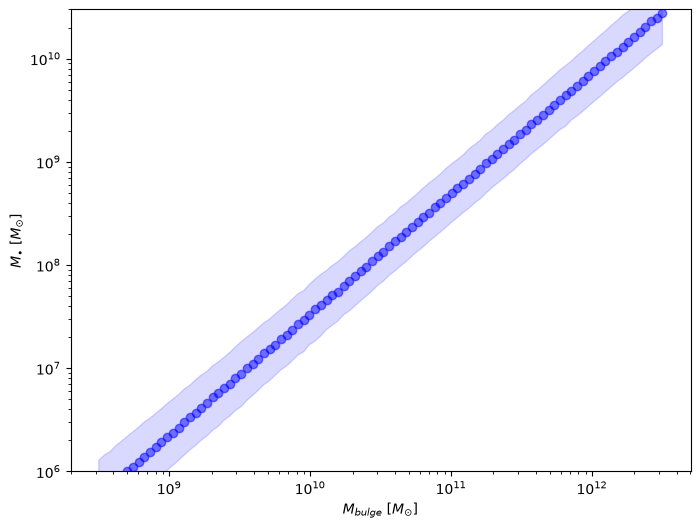

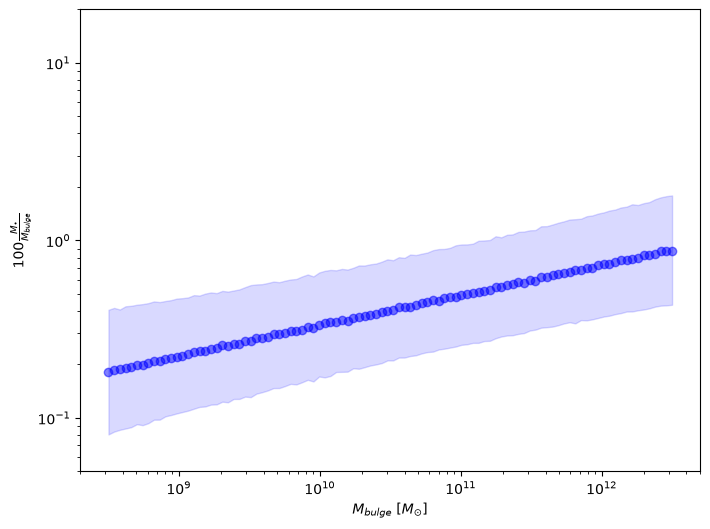

In [60]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

# reproduce the figure from Kormendy & Ho 2013, Figure 18
M_bulges = np.logspace(8.5, 12.5, 100)      # range of bulge masses
n_draws = 10000

# each draw = one realisation of (A, beta), applied to all bulge masses,
# with independent intrinsic scatter for every mass
sampled_MBHs = np.empty((n_draws, M_bulges.size))
for k in range(n_draws):
    A, beta = draw_relation_params(rng)
    sampled_MBHs[k] = sample_MBH(M_bulges, A, beta, rng)

median_MBH = np.median(sampled_MBHs, axis=0)      # shape (100,)

# ---- Plot 1: M_BH vs M_bulge ----
plt.figure(figsize=(8, 6))
plt.scatter(M_bulges, median_MBH, color='blue', alpha=0.5)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$M_{bulge}$ [$M_{\odot}$]')
plt.ylabel(r'$M_{\bullet}$ [$M_{\odot}$]')
plt.ylim(1e6, 3e10)
lo, hi = np.percentile(sampled_MBHs, [16, 84], axis=0)
plt.fill_between(M_bulges, lo, hi, color='blue', alpha=0.15)
plt.show()

# ---- Plot 2: M_BH / M_bulge in percent ----
plt.figure(figsize=(8, 6))
plt.scatter(M_bulges, 100 * median_MBH / M_bulges, color='blue', alpha=0.5)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$M_{bulge}$ [$M_{\odot}$]')
plt.ylabel(r'$100 \frac{M_{\bullet}}{M_{bulge}}$')
plt.ylim(0.05, 20)
lo, hi = np.percentile(100 * sampled_MBHs / M_bulges, [16, 84], axis=0)
plt.fill_between(M_bulges, lo, hi, color='blue', alpha=0.15)
plt.show()

We now have the galaxy number density in stellar mass and redshift, and a BH mass for each galaxy. To get the background we (i) give each galaxy a major-merger rate $r_i$, (ii) draw a mass ratio and BH masses for the binary, (iii) evaluate the population-averaged strain at a single observed GW frequency $f = 1/\mathrm{yr}$ (31.7 nHz, the PTA reference frequency), and (iv) sum $h_s^2$ weighted by how many binaries sit at that frequency:

$$h_c^2(f)=\frac{1}{f_{\rm sky}}\sum_i r_i\,\frac{dt}{d\ln f_r}\,h_{s,i}^2 ,\qquad A = h_c(1/\mathrm{yr})$$

Binaries are circular and GW-driven, and every major galaxy merger is assumed to yield a binary that reaches the PTA band ($f_{\rm bin}=1$). Mass ratios are *not* fixed to 1: they are drawn in `make_binaries`.

In [61]:
def hs2(Mc_kg, z, f_obs, dc_m):
    fr = f_obs * (1 + z)
    return (64*np.pi**(4/3)/10) * (G*Mc_kg)**(10/3) * fr**(4/3) / (c**8 * dc_m**2)

def dt_dlnf(Mc_kg, z, f_obs):
    fr = f_obs * (1 + z)
    return (5/96) * np.pi**(-8/3) * (G*Mc_kg)**(-5/3) * c**5 * fr**(-8/3)

zg   = np.linspace(0, 3.1, 2000)
dcg  = cosmo.comoving_distance(zg).to(u.m).value
dc_m = np.interp(z, zg, dcg)                         # fast lookup for 1e5+ objects

Number of major mergers between $z = 0$ and $z = 3.5$ for massive galaxies:
- 1.5-2.0 in big simulations (e.g.. Illustris)
- 0.5-1.1 from observations

We want to max out our values, so assume 2 mergers. To further max out, assume that all BHs hae mass ratio, $q=1$.

In [62]:
f_sky

0.0242406840554768

In [92]:
def calibrate_R0(m=0.8, n_mergers=2.0, z_max=3.5):
    """R0 [1/Gyr] such that a galaxy has n_mergers major mergers between z=0 and z_max."""
    zz = np.linspace(0, z_max, 500)
    t  = cosmo.lookback_time(zz).to(u.Gyr).value
    return n_mergers / trapezoid((1 + zz)**m, t)

R0 = calibrate_R0()                      # ≈ 0.025 /Gyr; print it to check
print(f"R0 = {R0:.4f} /Gyr")
def gwb_amplitude(z, logm, dc_m, f_sky, rng, R0=R0, m=0.8, q_min=1.0, f_bin=1.0):
    m1, m2 = make_binaries(logm, rng, q_min, z=z)
    Mc  = chirp_mass(m1, m2) * Msun
    r_i = f_bin * (R0 / Gyr) * (1 + z)**m          # s^-1
    f   = 1 / yr
    h2  = np.sum(r_i * dt_dlnf(Mc, z, f) * hs2(Mc, z, f, dc_m)) / f_sky
    return np.sqrt(h2), Mc

A_gwb, Mc = gwb_amplitude(z, logm, dc_m, f_sky, rng)
print(A_gwb)                                        

R0 = 0.1016 /Gyr
2.049009369333954e-15


NANOGrav constraints:
$A_{yr} = 2.4^{+0.7}_{-0.6}\times10^{-15}$

## Cross-check: two estimators of the same quantity

`A_direct` sums over galaxies (each a real object at its own $d_c$). `A_integral` uses the Phinney form
$h_c^2=\frac{4G^{5/3}}{3\pi^{1/3}c^2}f^{-4/3}\sum_i n_i M_{c,i}^{5/3}(1+z_i)^{-1/3}$ with $n_i = r_i\,\Delta t_k / V_k$.
They agree in expectation **only if both use the same $r_i$**. The earlier version of this cell used $f_{\rm pair}=0.03$, $m=1.5$ against $R_0$, $m=0.8$ above, giving a spurious ~50% mismatch.

In [9]:
def both_estimators(z, logm, dc_m, V, dt, f_sky, rng, R0=R0, m=0.8, q_min=0.25, f_bin=1.0, f=1/yr,
                    include_param_unc=True):
    m1, m2 = make_binaries(logm, rng, q_min, include_param_unc)
    Mc  = chirp_mass(m1, m2) * Msun
    r_i = f_bin * (R0 / Gyr) * (1 + z)**m                                   # s^-1, shared by both estimators
    A_direct = np.sqrt(np.sum(r_i * dt_dlnf(Mc, z, f) * hs2(Mc, z, f, dc_m)) / f_sky)
    n_i  = r_i * dt / (V * Mpc**3)                                           # mergers per comoving volume
    pref = 4*G**(5/3) / (3*np.pi**(1/3)*c**2) * f**(-4/3)
    A_integral = np.sqrt(pref * np.sum(n_i * Mc**(5/3) * (1 + z)**(-1/3)))
    return A_direct, A_integral

rng = np.random.default_rng(1)
z, logm, V, dt = sample_lightcone(area_deg2=10.0, rng=rng)
dc_m = np.interp(z, zg, dcg)
print(both_estimators(z, logm, dc_m, V, dt, f_sky, rng))    # should agree to ~1%

(np.float64(9.94493999527327e-16), np.float64(9.985956855603712e-16))


## Noise-free expectation (validates the Monte-Carlo machinery)

$$h_c^2=\sum_k\int dz\,\frac{dV_c}{dz}\,r(z)\,U(z)\int d\log M\,\Phi(\log M)\,\mathbb{E}\!\left[M_c^{5/3}\right],\quad U=h_s^2\,\frac{dt}{d\ln f_r}\Big|_{M_c=1}$$

The expectation over mass ratio and scatter is done by Monte Carlo on a mass grid; everything else is quadrature.

In [12]:
def E_Mc53(logM_grid, rng, A=0.49, beta=1.17, q_min=0.25, scatter=0.28, nmc=4000):
    out = np.empty_like(logM_grid)
    for i, lm in enumerate(logM_grid):
        q = rng.uniform(q_min, 1, nmc)
        a = sample_MBH(np.full(nmc, 10**lm), A, beta, rng, scatter)
        b = sample_MBH(q * 10**lm, A, beta, rng, scatter)
        out[i] = np.mean(chirp_mass(np.maximum(a, b), np.minimum(a, b))**(5/3))
    return out * Msun**(5/3)                       # kg^(5/3)

def expected_amplitude(rng, R0=R0, m=0.8, f_bin=1.0, f=1/yr, **kw):
    tot = 0.0
    for zlo, zhi, p, mc in bins:
        lg  = np.linspace(mc, 12.5, 120)
        I   = trapezoid(bin_density(lg, p) * E_Mc53(lg, rng, **kw), lg)
        zz  = np.linspace(zlo, zhi, 200)
        dVdz = cosmo.differential_comoving_volume(zz).to(u.Mpc**3/u.sr).value * 4*np.pi   # all-sky
        dc  = cosmo.comoving_distance(zz).to(u.m).value
        U   = hs2(1.0, zz, f, dc) * dt_dlnf(1.0, zz, f)
        r   = f_bin * (R0 / Gyr) * (1 + zz)**m
        tot += trapezoid(dVdz * r * U, zz) * I
    return np.sqrt(tot)

print("expected A(1/yr) =", expected_amplitude(np.random.default_rng(0)))      # ~4.8e-16 for the defaults

expected A(1/yr) = 1.0777000860902684e-15
